## Python Task:
### EDA Task
     1. Perform descriptive statistical analysis for numerical features
     2. Visualize the distribution of categorical features - race and gender
     3. Explore the relationship between readmission status and age
     4. Investigate correlations between numerical features
     5. Analyze the distribution of medication changes and total medications taken
     6. Examine the distribution of diagnoses categories
     7. Explore the distribution of patients across admission types, sources, and discharge
       dispositions
     8. Identify and visualize any outliers in the dataset, especially in numerical features
     9. Write an analysis report on performing exploratory data analysis (EDA) using Python
       in the context of building a fraud detection system for the healthcare management
       system.

In [20]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as sp
import seaborn as sns
import pandas as pd

df = pd.read_csv("diabetic_data.csv")
df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Step 1: Perform descriptive statistical analysis for numerical features

In [14]:
numerical_stats = df.select_dtypes([float,int]).describe()
print("Descriptive Statistical Analysis for Aumerical Features:")
numerical_stats

Descriptive Statistical Analysis for Aumerical Features:


,encounter_id,patient_nbr,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,1.017660e+05,1.017660e+05,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,1.652016e+08,5.433040e+07,2.024006,3.715642,5.754437,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566,7.422607
std,1.026403e+08,3.869636e+07,1.445403,5.280166,4.064081,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863,1.933600
min,1.252200e+04,1.350000e+02,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000
25%,8.496119e+07,2.341322e+07,1.000000,1.000000,1.000000,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000,6.000000
50%,1.523890e+08,4.550514e+07,1.000000,1.000000,7.000000,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000,8.000000
75%,2.302709e+08,8.754595e+07,3.000000,4.000000,7.000000,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000,9.000000
max,4.438672e+08,1.895026e+08,8.000000,28.000000,25.000000,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000,16.000000


### Step 2: Visualize the distribution of categorical features - race and gender

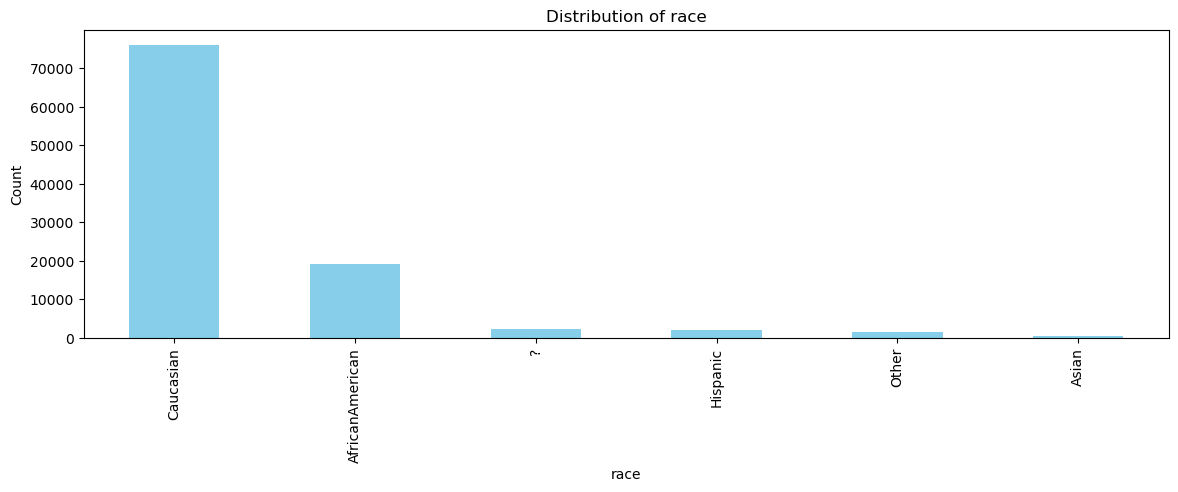

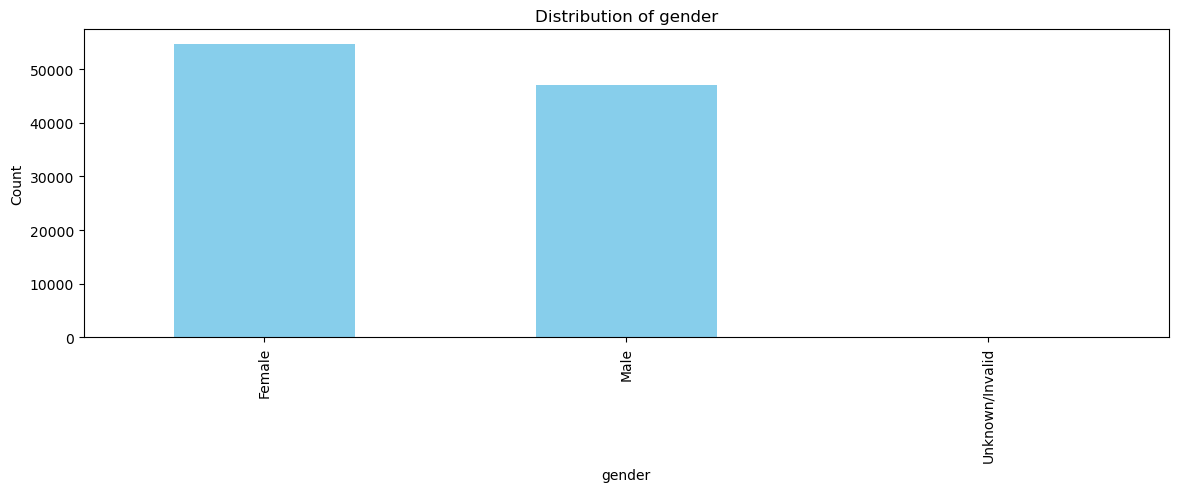

In [36]:
categorical_features = ['race','gender']
for feature in categorical_features:
    plt.figure(figsize=(14,4))
    df[feature].value_counts().plot(kind = 'bar', color = 'skyblue')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

### Step 3: Explore relationship between readmission status and age

##### pd.crosstab() is a pandas function used to count the frequency of combination of two or more categorical variables.

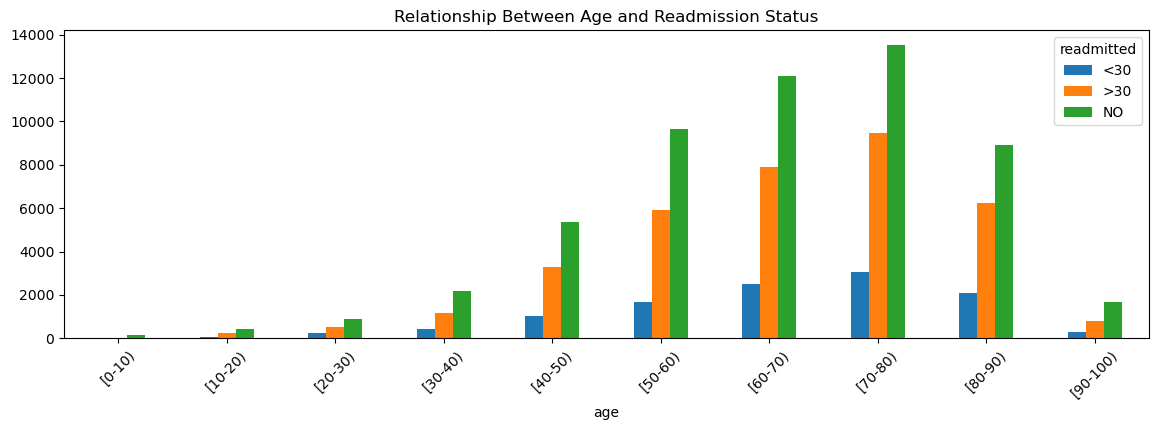

In [42]:
counts = pd.crosstab(df['age'],df['readmitted'])
counts.plot(kind = 'bar',figsize = (14,4))
plt.title('Relationship Between Age and Readmission Status')
plt.xticks(rotation = 45)
plt.show()

### Step 4: Investigate correlations between numerical features

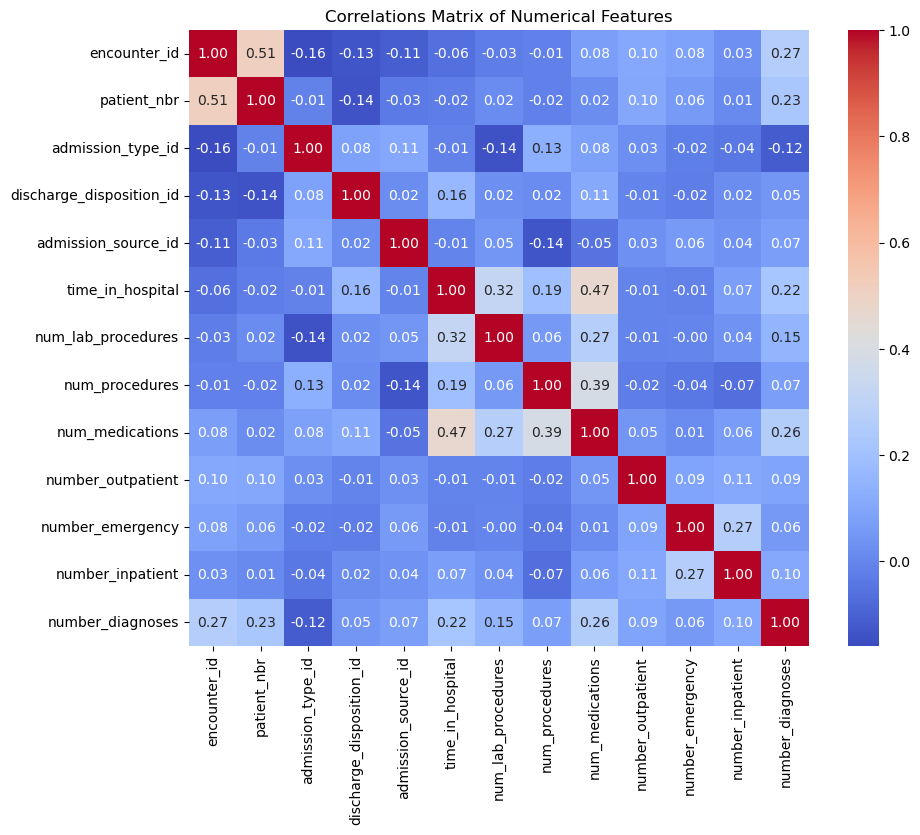

In [48]:
correlation_matrix = df.select_dtypes([float,int]).corr()
plt.figure(figsize = (10,8))
sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm',fmt = ".2f", annot_kws = {"size":10})
plt.title('Correlations Matrix of Numerical Features')
plt.show()

### Step 5: Analyze distribution of medication changes and total medications taken

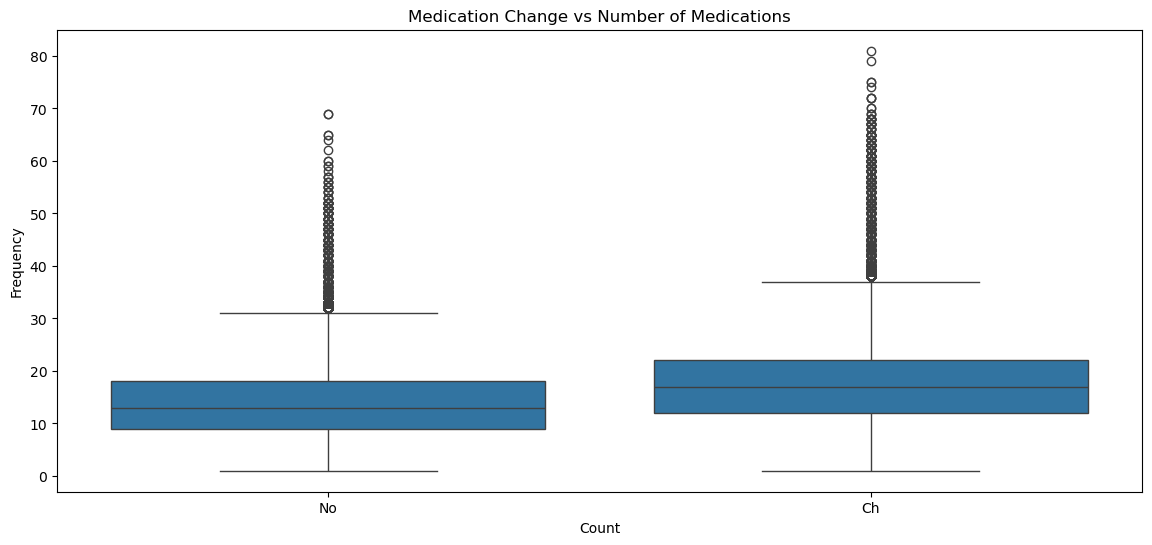

In [51]:
plt.figure(figsize=(14,6))
sns.boxplot(x='change', y='num_medications', data=df)
plt.title('Medication Change vs Number of Medications')
plt.xlabel('Count')
plt.ylabel('Frequency')
plt.show() 

 ### Step 6: Examine distribution of diagnoses categories 

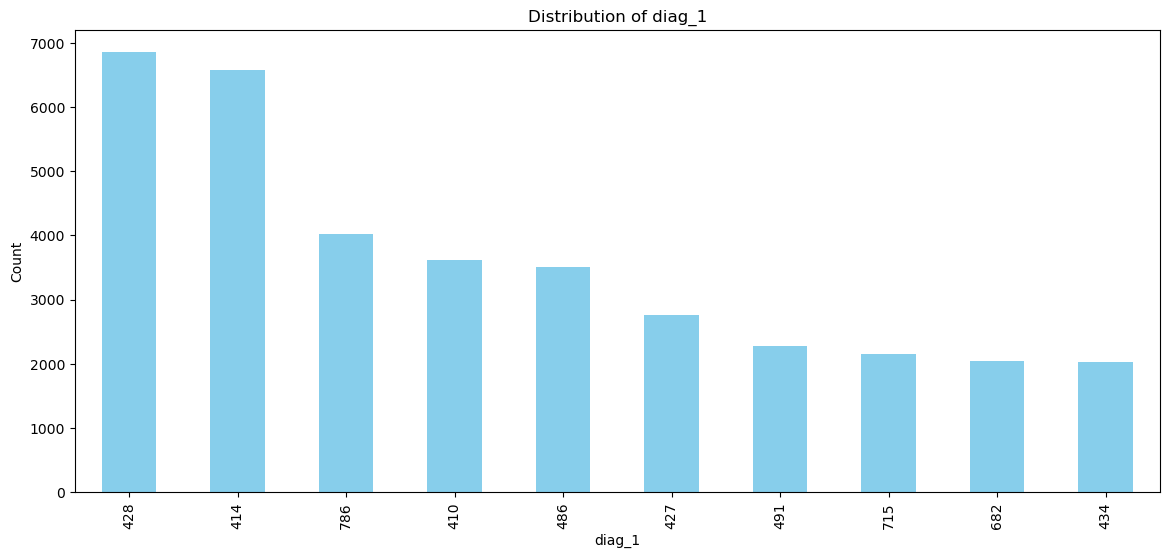

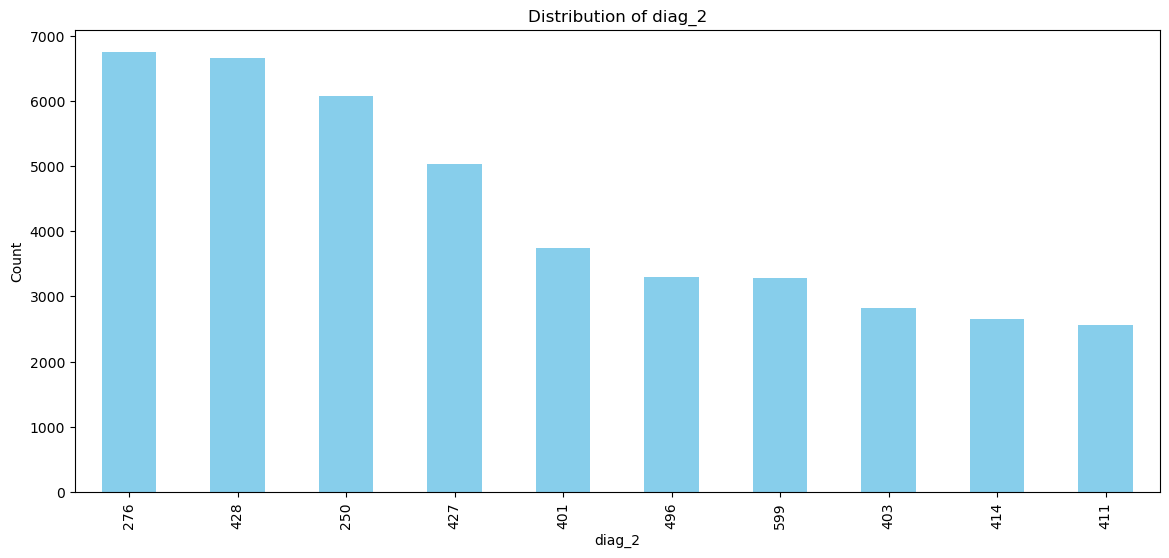

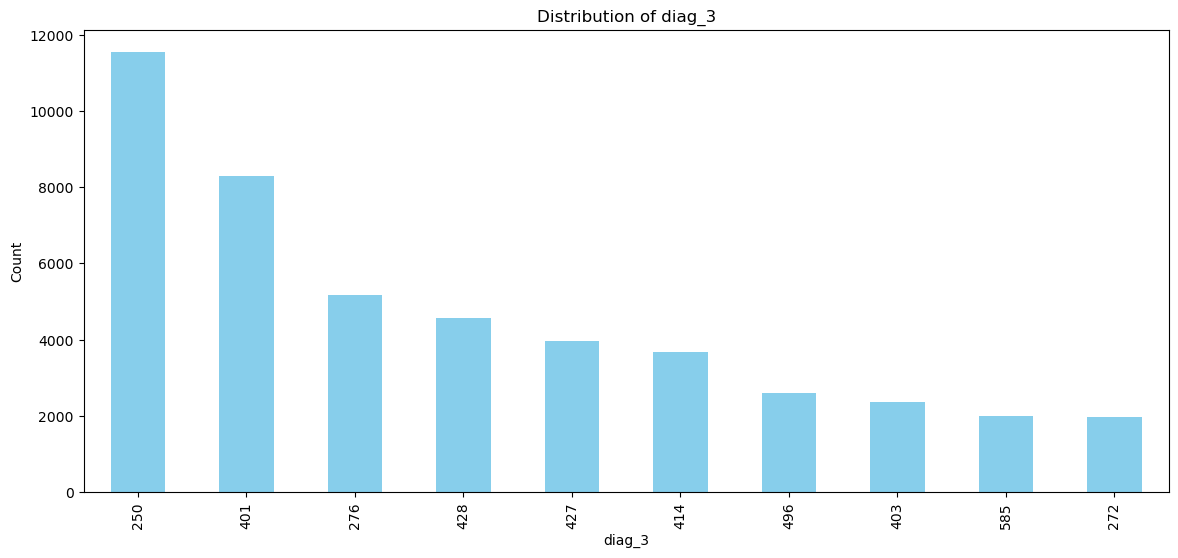

In [61]:
diagnosis_features = ['diag_1', 'diag_2', 'diag_3']
for feature in diagnosis_features:
    plt.figure(figsize=(14,6))
    df[feature].value_counts().head(10).plot(kind='bar', color = 'skyblue')
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

### Step 7: Explore distribution of patients across admission types, sources, and discharge dispositions.

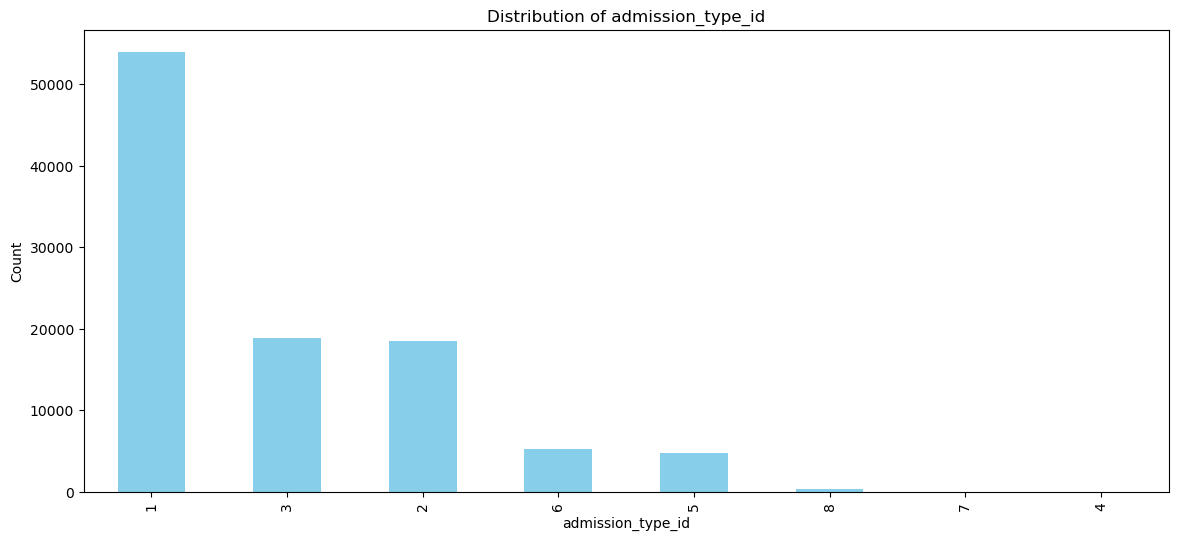

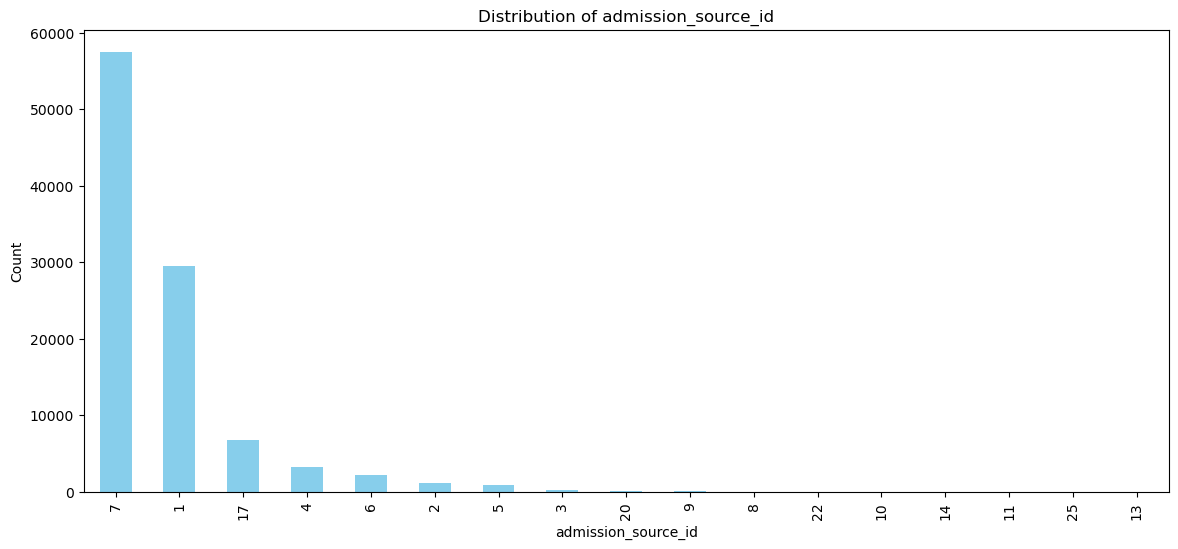

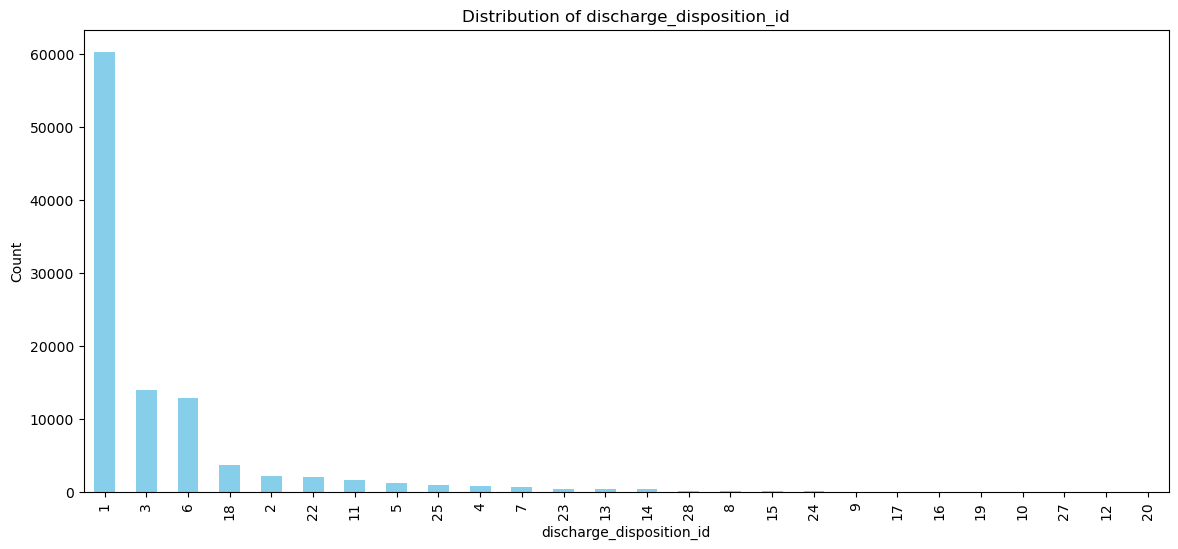

In [60]:
admission_features = ['admission_type_id', 'admission_source_id', 'discharge_disposition_id']
for feature in admission_features:
    plt.figure(figsize=(14,6))
    df[feature].value_counts().plot(kind='bar', color='skyblue')
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.show()

### Step 8: Identify and visualize any outliers in the dataset, especially in numerical features.

In [56]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns

# Remove ID columns (not useful for outlier detection)
numerical_cols = [col for col in numerical_cols 
                  if col not in ['encounter_id','patient_nbr']]

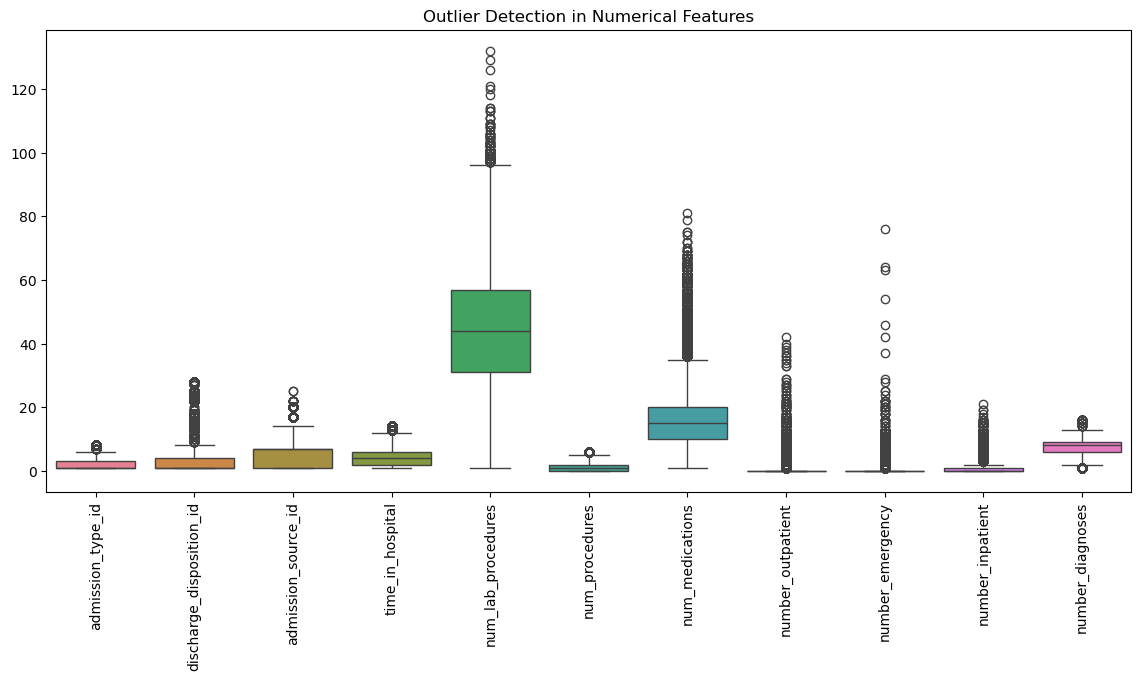

In [57]:
plt.figure(figsize=(14,6))
sns.boxplot(data=df[numerical_cols])
plt.xticks(rotation=90)
plt.title("Outlier Detection in Numerical Features")
plt.show()

### Step 9: Write an analysis report on performing exploratory data analysis (EDA) using Python in the context of building a fraud detection system for the healthcare management system.

#### Observations:

##### 1. Descriptive Statistics for Numerical Features:
    • The describe() function provides statistical summaries for numerical features like mean, standard deviation, minimum, maximum, and quartiles.
    • For instance, looking at num_medications, the average number of medications taken by patients is approximately 16, with a standard deviation of around 8.13.
    • Another example is num_lab_procedures, where the mean number of lab procedures conducted is about 43.10, with a standard deviation of approximately 19.68.
    
##### 2. Distribution of Categorical Features (Race and Gender):
    • Visualizations depict the distribution of categorical features such as race and gender.
    • For instance, the bar plot for race illustrates the count of patients belonging to different racial groups.
    • Similarly, the distribution of gender shows the count of male and female patients.
    
##### 3. Relationship between Age and Readmission Status:
    • The bar plot demonstrates the relationship between patients' ages and their readmission status.
    • It helps in understanding if there's any correlation between age groups and the likelihood of readmission.
    
##### 4. Correlation Matrix of Numerical Features:
    • The heatmap visualizes the correlation between different numerical features.
    • It helps identify potential relationships between variables, such as positive or negative correlations.
    
##### 5. Distribution of Medication Changes and Total Medications Taken:
    • The boxplot presents the distribution of medication changes concerning the total number of medications taken.
    • It assists in analyzing the impact of medication changes on the total medication count.
    
##### 6. Distribution of Diagnoses Categories:
    • Bar plots display the distribution of diagnoses categories, including 'diag_1', 'diag_2', and 'diag_3'.
    • These plots provide insights into the frequency of different diagnosis codes among patients.
    
##### 7. Distribution of Patients across Admission Types, Sources, and Discharge Dispositions:
    • Bar plots showcase the distribution of patients across various admission types, admission sources, and discharge dispositions.
    • Understanding these distributions is crucial for analyzing the patterns of patient admissions and discharges.
##### 8. Identify and visualize any outliers in the dataset, especially in numerical features:
    • More outliers are in lab procedures and Medications. 
These observations collectively contribute to exploratory data analysis (EDA), aiding in understanding the dataset's characteristics, relationships, and distributions.